# nuScenes → 3D Gaussian Splatting — Partie 2/3 : apport des sweeps et nombre d'itérations

**Contenu :** expérience 3 (A' contre B, puis B 7k contre B' 30k) et expérience 3'/5 (courbes train/validation par checkpoint).

**Prérequis dans `/kaggle/working`** (produits par les notebooks précédents et déjà sauvegardés) :
- `data/sets/nuscenes` (dataset nuScenes mini)
- `outputs/nerf_data_A_prime`, `outputs/nerf_data_B`, `outputs/nerf_data_B_30k`, `outputs/nerf_data_tvt` (entraînements)
- `eval_*.json`, `renders_test/`, `renders_split/`, `exp5_curves.json`

**Avant tout** (menu *Settings*) : **Accelerator** = GPU T4 x2, **Internet** = activé.
Sur Kaggle, un *Restart session* efface les paquets installés : relance la section « En-tête » ci-dessous.
Le détail des choix d'installation (pas de `nuscenes-devkit`, numpy 2.x) est expliqué dans la partie 1.


---
# En-tête : installation, dataset et fonctions communes


In [ ]:
# Vérifie si le cache gsplat a été conservé par la persistance
import os
if os.path.isdir('/kaggle/working/torch_extensions'):
    print('✅ cache gsplat présent : pas de recompilation')
else:
    print('❌ pas de cache : gsplat va compiler (~17 min)')

## 1. Prérequis

In [ ]:
import socket, torch, torchvision

try:
    socket.gethostbyname('pypi.org')
    print('Internet : OK')
except Exception as e:
    raise RuntimeError('Internet désactivé → Settings > Internet > On') from e

if not torch.cuda.is_available():
    raise RuntimeError('Pas de GPU → Settings > Accelerator > GPU T4 x2')

print('GPU         :', torch.cuda.get_device_name(0))
print('PyTorch     :', torch.__version__)
print('torchvision :', torchvision.__version__)
print('CUDA        :', torch.version.cuda)


In [ ]:
# nvcc est indispensable : gsplat compile ses kernels CUDA à la volée
!which nvcc && nvcc --version | tail -2


## 2. Installation

Les 45 dépendances de nerfstudio (`tyro`, `viser`, `gsplat`, `pyquaternion`…) sont installées
explicitement, **sans** `nuscenes-devkit`. Puis nerfstudio lui-même en `--no-deps`, pour que pip ne
le réintroduise pas.

Les versions de `torch`, `torchvision` et `numpy` déjà présentes sont figées par un fichier de
contraintes : c'est leur remplacement qui provoquait `libcuda.so cannot found`.

Compter une dizaine de minutes.

In [ ]:
import torch, torchvision, numpy, pathlib

pathlib.Path('/kaggle/working/constraints.txt').write_text(
    f"torch=={torch.__version__.split('+')[0]}\n"
    f"torchvision=={torchvision.__version__.split('+')[0]}\n"
    f"numpy=={numpy.__version__}\n"
)

# Liste extraite des métadonnées officielles de nerfstudio 1.1.5, moins nuscenes-devkit
deps = """appdirs>=1.4
av>=9.2.0
comet-ml>=3.33.8
cryptography>=38
tyro>=0.6.6
gdown>=4.6.0
ninja>=1.10
h5py>=2.9.0
imageio>=2.21.1
ipywidgets>=7.6
jaxtyping>=0.2.15
jupyterlab>=3.3.4
matplotlib>=3.6.0
mediapy>=1.1.0
msgpack>=1.0.4
msgpack-numpy>=0.4.8
nerfacc==0.5.2
open3d>=0.16.0
opencv-python-headless==4.10.0.84
Pillow>=10.3.0
plotly>=5.7.0
protobuf!=3.20.0,<=3.20.3
pyngrok>=5.1.0
python-socketio>=5.7.1
pyquaternion>=0.9.9
requests
rich>=12.5.1
scikit-image>=0.19.3
splines==0.3.0
tensorboard>=2.13.0
torchmetrics[image]>=1.0.1
typing-extensions>=4.4.0
viser==0.2.7
wandb>=0.13.3
xatlas
trimesh>=3.20.2
timm==0.6.7
gsplat==1.4.0
pytorch-msssim
pathos
packaging
fpsample
tensorly
rawpy>=0.18.1
pymeshlab>=2022.2.post2
"""
pathlib.Path('/kaggle/working/requirements.txt').write_text(deps)
print(len([l for l in deps.splitlines() if l.strip()]), 'dépendances à installer')


In [ ]:
!pip install -r /kaggle/working/requirements.txt -c /kaggle/working/constraints.txt


In [ ]:
!pip install nerfstudio==1.1.5 --no-deps


In [ ]:
# gsplat déjà compilé : construit UNE fois (~15-20 min), puis réinstallé en quelques secondes
import glob
whl = glob.glob('/kaggle/working/wheels/gsplat-*.whl')
if not whl:
    print('Aucune wheel : compilation unique de gsplat...')
    !TORCH_CUDA_ARCH_LIST="7.5" MAX_JOBS=2 pip wheel "git+https://github.com/nerfstudio-project/gsplat.git@v1.4.0" --no-deps --no-build-isolation -w /kaggle/working/wheels
    whl = glob.glob('/kaggle/working/wheels/gsplat-*.whl')
!pip install --no-deps --force-reinstall -q {whl[0]}
!ls -lh /kaggle/working/wheels

Les avertissements `protobuf ... is incompatible` concernant `google-cloud-*`, `shap` ou `grain`
sont **sans effet ici** : ce sont des paquets préinstallés par Kaggle que ce pipeline n'utilise pas.
nerfstudio impose `protobuf<=3.20.3`, ce qui les gêne, eux, pas nous.

In [ ]:
# Contrôle : numpy doit être resté en 2.x et PyTorch voir toujours le GPU
import torch, numpy, nerfstudio, tyro, gsplat, viser
from pyquaternion import Quaternion
from importlib.metadata import version

print('torch      :', torch.__version__, '| CUDA :', torch.cuda.is_available())
print('numpy      :', numpy.__version__)
print('nerfstudio :', version('nerfstudio'))
print('tyro, gsplat, viser, pyquaternion : OK')

assert torch.cuda.is_available(), 'PyTorch a perdu le GPU'
assert numpy.__version__.startswith('2'), 'numpy a été rétrogradé — nuscenes-devkit a dû être tiré'
print('\nInstallation cohérente ✅')

## 3. Compilation de gsplat

Isolée volontairement : elle prend plusieurs minutes, autant qu'elle échoue ici plutôt qu'au milieu
de l'entraînement.

- **`MAX_JOBS=2`** : la wheel de gsplat ne contient aucun binaire précompilé (`py3-none-any`,
  1693 sources CUDA) — il compile toujours à la première utilisation, et son code fixe `MAX_JOBS=10`
  par défaut. Dix `nvcc` en parallèle saturent la RAM de la machine, le noyau tue un processus, et
  ninja rapporte `build stopped: subcommand failed`. C'est très probablement ce que tu as eu.
- **`TORCH_EXTENSIONS_DIR`** dans `/kaggle/working` : le cache par défaut (`~/.cache`) disparaît au
  redémarrage, celui-ci survit.

Ces variables doivent être posées **avant** le premier `import gsplat`.
Si ça échoue encore par manque de mémoire, descends à `MAX_JOBS=1`.

In [ ]:
import os

os.environ['MAX_JOBS'] = '2'
os.environ['TORCH_EXTENSIONS_DIR'] = '/kaggle/working/torch_extensions'
os.makedirs(os.environ['TORCH_EXTENSIONS_DIR'], exist_ok=True)

print('MAX_JOBS             :', os.environ['MAX_JOBS'])
print('TORCH_EXTENSIONS_DIR :', os.environ['TORCH_EXTENSIONS_DIR'])


In [ ]:
# Déclenche la compilation CUDA (longue la 1re fois, instantanée ensuite via le cache)
import time
t0 = time.time()
from gsplat.cuda._backend import _C
print(f'gsplat compilé et chargé en {time.time() - t0:.0f}s')


In [ ]:
import torch
print(torch.__version__, torch.version.cuda)   # ex. 2.4.0  12.4

In [ ]:
# Rendu réel sur GPU : si ça passe, l'entraînement passera aussi
import torch
from gsplat import rasterization

N = 100
g = torch.Generator(device='cuda').manual_seed(0)
means     = torch.randn(N, 3, device='cuda', generator=g)
quats     = torch.randn(N, 4, device='cuda', generator=g)
scales    = torch.rand(N, 3, device='cuda', generator=g) * 0.1
opacities = torch.rand(N, device='cuda', generator=g)
colors    = torch.rand(N, 3, device='cuda', generator=g)
viewmats  = torch.eye(4, device='cuda')[None]
Ks = torch.tensor([[[300., 0., 150.], [0., 300., 100.], [0., 0., 1.]]], device='cuda')

out, alpha, meta = rasterization(means, quats, scales, opacities, colors,
                                 viewmats, Ks, width=300, height=200)
print('Rendu test OK — shape :', tuple(out.shape))


## 4. Dataset nuScenes (mini)

~4 Go. Ignoré si déjà présent.

💡 Sans téléchargement : nuScenes mini existe comme dataset public Kaggle. En l'attachant via
**Add Input**, il apparaît sous `/kaggle/input/…` — il suffit alors de pointer `DATAROOT` dessus
et de sauter la cellule suivante.

In [ ]:
DATAROOT   = '/kaggle/working/data/sets/nuscenes'
OUTPUT_DIR = '/kaggle/working/nerf_data'
VERSION    = 'v1.0-mini'

In [ ]:
%%bash
set -e
DEST=/kaggle/working/data/sets/nuscenes
mkdir -p $DEST

if [ ! -d "$DEST/v1.0-mini" ]; then
    echo 'Téléchargement de nuScenes v1.0-mini (~4 Go)...'
    wget --progress=dot:giga https://www.nuscenes.org/data/v1.0-mini.tgz -O /kaggle/working/v1.0-mini.tgz
    tar -xzf /kaggle/working/v1.0-mini.tgz -C $DEST
    rm -f /kaggle/working/v1.0-mini.tgz
    echo 'Terminé'
else
    echo 'Dataset déjà présent'
fi
du -sh $DEST


## Fonctions communes

In [ ]:
# Fonctions utilitaires communes (reprises du notebook 1, section 5)
import os, json
import numpy as np

def load_tables(dataroot, version):
    """Charge les 6 tables JSON nuScenes utiles : scene, sample, sample_data, sensor,
    calibrated_sensor, ego_pose. Renvoie un dict {nom: liste d'enregistrements}."""
    p = os.path.join(dataroot, version)
    names = ['scene', 'sample', 'sample_data', 'sensor', 'calibrated_sensor', 'ego_pose']
    return {n: json.load(open(os.path.join(p, f'{n}.json'))) for n in names}

def quat_to_rotmat(q):
    """Quaternion nuScenes [w, x, y, z] → matrice de rotation 3x3."""
    w, x, y, z = np.array(q, dtype=float) / np.linalg.norm(q)
    return np.array([
        [1 - 2*(y*y + z*z),     2*(x*y - z*w),     2*(x*z + y*w)],
        [    2*(x*y + z*w), 1 - 2*(x*x + z*z),     2*(y*z - x*w)],
        [    2*(x*z - y*w),     2*(y*z + x*w), 1 - 2*(x*x + y*y)],
    ])

def get_T(rec):
    """Enregistrement nuScenes (translation + rotation) → matrice homogène 4x4."""
    T = np.eye(4)
    T[:3, :3] = quat_to_rotmat(rec['rotation'])
    T[:3, 3]  = np.array(rec['translation'], dtype=float)
    return T

# OpenCV (nuScenes) → OpenGL (nerfstudio)
OPENCV_TO_OPENGL = np.diag([1, -1, -1, 1])


## Restauration des résultats sauvegardés


In [ ]:
# Restauration des résultats sauvegardés (modèles, rendus, courbes) depuis le Dataset Kaggle
# Ajouter d'abord le Dataset au notebook : panneau de droite > Add Input > Datasets > Your Datasets.
import os, glob, shutil, zipfile

SRC = '/kaggle/input/syntha-drive-resultats'   # ← adapter au nom de ton Dataset
DST = '/kaggle/working'

if not os.path.isdir(SRC):
    print(f'❌ {SRC} introuvable : ajoute le Dataset en Input (ou corrige SRC)')
elif os.path.isdir(f'{DST}/outputs'):
    print('✅ résultats déjà présents dans /kaggle/working : rien à faire')
else:
    zips = glob.glob(f'{SRC}/**/*.zip', recursive=True)
    if zips:                                   # archive non décompressée par Kaggle
        for z in zips:
            zipfile.ZipFile(z).extractall(DST)
    else:                                      # Kaggle a décompressé : on copie le contenu
        racine = SRC
        sous = os.listdir(SRC)                 # cas d'un unique dossier englobant
        if len(sous) == 1 and os.path.isdir(f'{SRC}/{sous[0]}') and not os.path.isdir(f'{SRC}/outputs'):
            racine = f'{SRC}/{sous[0]}'
        shutil.copytree(racine, DST, dirs_exist_ok=True)   # copie : les cellules réécrivent certains dossiers
    print('✅ résultats restaurés :', sorted(os.listdir(DST)))


---
# Fin de l'en-tête


# Expérience 3 : Modele A_prime et model B

Je rappelle que j'ai entraîné un modele A sur seulement les frames is_key_frame. Le découpage train/test est de ration 90%/10% géré par nerfstudio. Je crois qu'il prend les images d’entraînement réparties uniformément sur toute la séquence (np.linspace), et les images de test sont les trous entre elles, dispersés le long du trajet. Pour tes 39 images : 36 en entraînement et 3 en test, éparpillées.

C’est donc de l’interpolation : chaque image de test est entourée d’images d’entraînement proches. C’est cette même logique de découpage que je vais utiliser pour entrainer un premier modèle A’ sur seulement les is_key_frame et un autre B sur les is_key_frame et les sweep. L'idée est de comparer le gain quand on passe de A' à B.

Cette comparaison n'a de sens que si on évalue les deux modèles sur les mêmes données test. Le tableau ci dessous récapitule le split.

| Modèle | Train : keyframes | Train : sweeps | Test |
|---|---|---|---|
| **A'** | 31 | 0 | 8 keyframes + 44 sweeps = **52** |
| **B** | 31 | 141 | **les mêmes 52** |

In [31]:
# Export avec découpage train/test FIXE, identique pour A' et B
# Test = une keyframe sur 5 + les sweeps à moins de gap_s d'elle (fenêtres de test).
# Aucune image de test n'est vue à l'entraînement, ni par A' ni par B.
import os, json, shutil
import numpy as np

OPENCV_TO_OPENGL = np.diag([1, -1, -1, 1])

def export_split(dataroot, output_dir, version='v1.0-mini', channel='CAM_FRONT',
                 scene_idx=0, with_sweeps=False, test_every=5, gap_s=0.25):
    t = load_tables(dataroot, version)
    by = lambda tab: {r['token']: r for r in tab}
    sensors, calibs, poses = by(t['sensor']), by(t['calibrated_sensor']), by(t['ego_pose'])
    sds = by(t['sample_data'])

    # Toutes les images de la caméra dans la scène, dans l'ordre (chaîne 'next')
    first_sample = t['scene'][scene_idx]['first_sample_token']
    sd = next(s for s in t['sample_data']
              if s['sample_token'] == first_sample and s['is_key_frame']
              and sensors[calibs[s['calibrated_sensor_token']]['sensor_token']]['channel'] == channel)
    chain = []
    while sd:
        chain.append(sd)
        sd = sds.get(sd['next'])

    keyframes = [s for s in chain if s['is_key_frame']]
    test_ts = [s['timestamp'] for i, s in enumerate(keyframes) if i % test_every == test_every // 2]

    shutil.rmtree(output_dir, ignore_errors=True)
    os.makedirs(f'{output_dir}/images')
    frames, train, test = [], [], []
    for s in chain:
        near_test = min(abs(s['timestamp'] - ts) for ts in test_ts) <= gap_s * 1e6
        if s['is_key_frame']:
            split = 'test' if s['timestamp'] in test_ts else 'train'
        elif near_test:
            split = 'test'    # sweep dans une fenêtre de test : jamais vu à l'entraînement
        elif with_sweeps:
            split = 'train'
        else:
            continue
        T = get_T(poses[s['ego_pose_token']]) @ get_T(calibs[s['calibrated_sensor_token']]) @ OPENCV_TO_OPENGL
        name = f"./images/{s['token']}.{s['fileformat']}"
        shutil.copy(os.path.join(dataroot, s['filename']), os.path.join(output_dir, name))
        frames.append({'file_path': name, 'transform_matrix': T.tolist()})
        (test if split == 'test' else train).append(name)

    K = calibs[chain[0]['calibrated_sensor_token']]['camera_intrinsic']
    data = {'fl_x': K[0][0], 'fl_y': K[1][1], 'cx': K[0][2], 'cy': K[1][2],
            'w': chain[0]['width'], 'h': chain[0]['height'], 'frames': frames,
            'train_filenames': train, 'val_filenames': test, 'test_filenames': test}
    with open(f'{output_dir}/transforms.json', 'w') as f:
        json.dump(data, f, indent=4)
    print(f"{output_dir} : {len(train)} images d'entraînement, {len(test)} de test")

export_split(DATAROOT, '/kaggle/working/nerf_data_A_prime', with_sweeps=False)
export_split(DATAROOT, '/kaggle/working/nerf_data_B', with_sweeps=True)

/kaggle/working/nerf_data_A_prime : 31 images d'entraînement, 52 de test
/kaggle/working/nerf_data_B : 172 images d'entraînement, 52 de test


In [32]:
   #!ns-train splatfacto --data /kaggle/working/nerf_data_A_prime --output-dir /kaggle/working/outputs --max-num-iterations 7000 --viewer.quit-on-train-completion True --pipeline.model.num-downscales 2 nerfstudio-data

In [33]:
#!ns-train splatfacto --data /kaggle/working/nerf_data_B --output-dir /kaggle/working/outputs --max-num-iterations 7000 --viewer.quit-on-train-completion True --pipeline.model.num-downscales 2 nerfstudio-data

In [34]:
!ls /kaggle/working/outputs/

exp6_L3     nerf_data	       nerf_data_B	nerf_data_tvt
exp7_3cams  nerf_data_A_prime  nerf_data_B_30k	nerf_data_tvt_lidar


In [35]:
# # Scores sur les 52 images de test : PSNR et SSIM plus hauts = mieux, LPIPS plus bas = mieux
# import glob, json
# for name in ['nerf_data_A_prime', 'nerf_data_B']:
#     cfg = sorted(glob.glob(f'/kaggle/working/outputs/{name}/splatfacto/*/config.yml'))[-1]
#     !TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD=1 ns-eval --load-config {cfg} --output-path /kaggle/working/eval_{name}.json --render-output-path /kaggle/working/eval_renders/{name}
#     r = json.load(open(f'/kaggle/working/eval_{name}.json'))['results']
#     print(f"{name} | PSNR {r['psnr']:.2f} | SSIM {r['ssim']:.3f} | LPIPS {r['lpips']:.3f}")

| Modèle | Train | Test | PSNR ↑ | SSIM ↑ | LPIPS ↓ |
|---|---|---|---|---|---|
| **A'** (keyframes) | 31 | 52 | 19.31 | 0.698 | 0.513 |
| **B** (keyframes + sweeps) | 172 | 52 | **21.72** | **0.763** | 0.515 |
| *Écart B − A'* | | | *+2.41 dB* | *+0.065* | *+0.002* |

### Analyse
- **PSNR : +2,41 dB pour B.** L'erreur quadratique moyenne est divisée par environ 1,7. Les couleurs et
  la position des objets sont plus justes sur les vues de test.
- **SSIM : +0,065 pour B.** Les structures (contours, formes) sont mieux reproduites. C'est cohérent avec
  une **meilleure géométrie** : chaque point de la rue est vu depuis environ 5 fois plus de positions,
  donc la profondeur est mieux contrainte.
- **LPIPS : inchangé (≈ 0,51).** Le rendu n'est pas perçu comme plus net : les textures fines et les
  détails restent flous.
- **Hypothèse** : à 7000 itérations, B voit chaque image environ 41 fois, contre environ 226 fois pour A'.
  Il a eu moins d'occasions d'affiner les détails, ce qui pourrait masquer une partie du gain.
- **Limites** : une seule scène, un seul entraînement par modèle (sans répétition, l'écart n'est pas
  mesuré avec certitude), et 52 images de test concentrées sur 8 endroits de la rue.

### Conclusion
Ajouter les sweeps améliore la **fidélité géométrique et structurelle** des vues de test (PSNR, SSIM),
mais pas encore la **qualité perceptuelle** (LPIPS), à budget d'entraînement égal.

### Questions
1. Avec plus d'itérations (par exemple 15 000), B améliore-t-il aussi le LPIPS ?
2. L'écart A' / B est-il stable si on répète l'entraînement (variabilité due au hasard) ?
3. Les résultats sont-ils les mêmes sur les 8 keyframes et sur les 44 sweeps de test, pris séparément ?
4. Le gain se confirme-t-il sur d'autres scènes nuScenes ?
5. Le gain tient-il pour des vues **réellement nouvelles**, par exemple la trajectoire décalée sur le côté ?

## Rappel sur les Métriques d'évaluation

Chaque image est un tableau de $H \times W \times 3$ valeurs dans $[0, 1]$ (ici $900 \times 1600 \times 3 \approx 4{,}3$ millions).
On compare le **rendu** $x$ du modèle à la **vraie photo** $y$, prise depuis la même pose.

### PSNR (*Peak Signal-to-Noise Ratio*), en dB, plus grand = mieux

On part de l'erreur quadratique moyenne sur les $N$ valeurs de pixels :

$$\text{MSE} = \frac{1}{N}\sum_{i=1}^{N} (x_i - y_i)^2$$

puis on la passe en échelle logarithmique (décibels) :

$$\text{PSNR} = 10 \cdot \log_{10}\left(\frac{1}{\text{MSE}}\right) \qquad \Longleftrightarrow \qquad \text{MSE} = 10^{-\text{PSNR}/10}$$

- le $1/\cdot$ retourne l'échelle (plus haut = mieux) ; le $\log$ rend lisibles des erreurs de plusieurs ordres de grandeur ;
- $+10$ dB = erreur divisée par 10 ; $+3$ dB = erreur divisée par 2 (car $10^{0{,}3} \approx 2$) ;
- $\sqrt{\text{MSE}}$ donne l'erreur typique par pixel : 20 dB $\to$ ≈ 10 %, 30 dB $\to$ ≈ 3 %.

**Limite** : comparaison pixel par pixel. Le PSNR est indulgent avec le **flou** (erreurs modérées partout) et sévère avec un léger **décalage**.
En reconstruction 3D, un décalage signale une erreur de géométrie : il est donc légitime de le pénaliser.

### SSIM (*Structural Similarity*), dans $[-1, 1]$, plus haut = mieux

On compare les images **par patchs** (fenêtre glissante $11 \times 11$, pondérée par une gaussienne $\sigma = 1{,}5$).
Pour un patch du rendu $x$ et le patch correspondant de la photo $y$, de $N$ pixels :

$$\mu_x = \frac{1}{N}\sum_i x_i \qquad \sigma_x = \sqrt{\frac{1}{N}\sum_i (x_i - \mu_x)^2} \qquad \sigma_{xy} = \frac{1}{N}\sum_i (x_i - \mu_x)(y_i - \mu_y)$$

- $\mu$ : **luminosité** moyenne du patch ;
- $\sigma$ : **contraste** (texturé ou lisse) ;
- $\sigma_{xy}$ : **structure** (les motifs et contours vont-ils dans le même sens ?).

$$\text{SSIM}(x, y) = \frac{(2\mu_x\mu_y + C_1)(2\sigma_{xy} + C_2)}{(\mu_x^2 + \mu_y^2 + C_1)(\sigma_x^2 + \sigma_y^2 + C_2)}$$

$C_1, C_2$ sont de petites constantes qui évitent les divisions par zéro. SSIM $= 1$ si les patchs sont identiques.
Le score final est la **moyenne sur tous les patchs** de l'image.

**Intérêt** : le flou écrase les détails, donc $\sigma_x$ et $\sigma_{xy}$ baissent et la SSIM chute, là où le PSNR restait indulgent.

### LPIPS (*Learned Perceptual Image Patch Similarity*), plus bas = mieux

Les deux images passent dans un réseau pré-entraîné (AlexNet), et on compare leurs **caractéristiques internes** plutôt que leurs pixels.
C'est la mesure la plus proche du **jugement humain** (netteté, textures, artefacts).

**Les trois sont complémentaires** : PSNR = exactitude des pixels, SSIM = structures locales, LPIPS = qualité perçue.

In [36]:
# # Rend les 52 vues de test de A' et B (images jamais vues à l'entraînement)
# import glob
# for name in ['nerf_data_A_prime', 'nerf_data_B']:
#     cfg = sorted(glob.glob(f'/kaggle/working/outputs/{name}/splatfacto/*/config.yml'))[-1]
#     !TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD=1 ns-render dataset --load-config {cfg} --split test --rendered-output-names rgb --output-path /kaggle/working/renders_test/{name}

In [37]:
# Vidéo [vraie photo | A' | B] sur les vues de test, dans l'ordre du trajet
import glob, os, json, numpy as np, mediapy as media
from PIL import Image, ImageDraw
from IPython.display import Video

def renders(name):
    files = glob.glob(f'/kaggle/working/renders_test/{name}/**/*.jpg', recursive=True)
    return {os.path.splitext(os.path.basename(f))[0]: f for f in files}

rA, rB = renders('nerf_data_A_prime'), renders('nerf_data_B')
print(len(rA), 'rendus A\'', '|', len(rB), 'rendus B')

# Ordre chronologique grâce aux timestamps nuScenes (le nom de fichier = token)
sds = {s['token']: s for s in json.load(open(f'{DATAROOT}/v1.0-mini/sample_data.json'))}
tokens = sorted(set(rA) & set(rB), key=lambda t: sds[t]['timestamp'])

def tile(path, label, size=(533, 300)):
    im = Image.open(path).convert('RGB').resize(size)
    ImageDraw.Draw(im).text((10, 10), label, fill=(255, 255, 0))
    return np.array(im)

frames = []
for t in tokens:
    photo = glob.glob(f'/kaggle/working/nerf_data_A_prime/images/{t}.*')[0]
    frames.append(np.concatenate([tile(photo, 'Photo'), tile(rA[t], "A'"), tile(rB[t], 'B')], axis=1))

os.makedirs('/kaggle/working/renders', exist_ok=True)
media.write_video('/kaggle/working/renders/test_photo_Aprime_B.mp4', frames, fps=3)
Video('/kaggle/working/renders/test_photo_Aprime_B.mp4', embed=True, width=1000)

52 rendus A' | 52 rendus B


Je suis obligé de reconnaître qu'avec mes yeux d'humain il m'est difficile de trancher sur lequel des deux models est plus performant.
C’est cohérent avec le LPIPS quasi identique : à l’œil, la différence est trop faible pour trancher.

B meilleur que A' sur 49 / 52 images


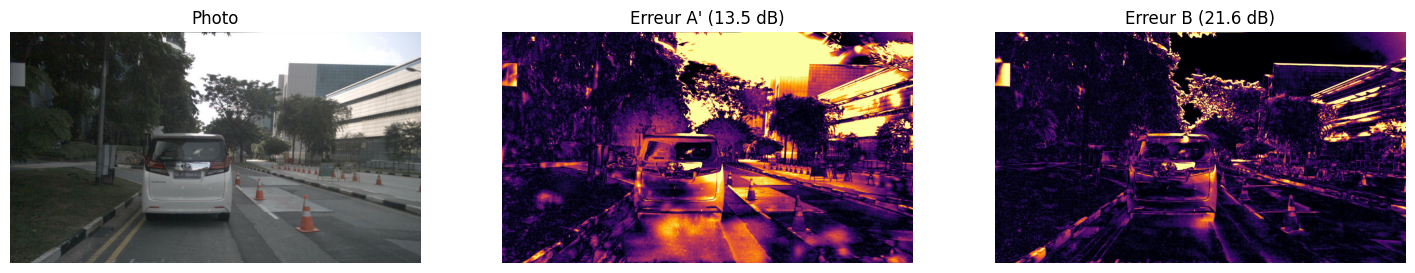

In [38]:
# Score image par image + carte d'erreur : où chaque modèle se trompe-t-il ?
import glob, os, json, numpy as np, matplotlib.pyplot as plt
from PIL import Image

def renders(name):
    files = glob.glob(f'/kaggle/working/renders_test/{name}/**/*.jpg', recursive=True)
    return {os.path.splitext(os.path.basename(f))[0]: f for f in files}

rA, rB = renders('nerf_data_A_prime'), renders('nerf_data_B')
sds = {s['token']: s for s in json.load(open('/kaggle/working/data/sets/nuscenes/v1.0-mini/sample_data.json'))}
tokens = sorted(set(rA) & set(rB), key=lambda t: sds[t]['timestamp'])

def load(p, size=None):
    im = Image.open(p).convert('RGB')
    return np.asarray(im.resize(size) if size else im, dtype=np.float32) / 255

psnr = lambda a, b: 10 * np.log10(1 / np.mean((a - b) ** 2))

scores, imgs = [], []
for t in tokens:
    y = load(glob.glob(f'/kaggle/working/nerf_data_A_prime/images/{t}.*')[0])
    size = (y.shape[1], y.shape[0])
    a, b = load(rA[t], size), load(rB[t], size)
    scores.append((psnr(a, y), psnr(b, y)))
    imgs.append((y, a, b))
scores = np.array(scores)
print(f"B meilleur que A' sur {(scores[:, 1] > scores[:, 0]).sum()} / {len(scores)} images")

# Carte d'erreur |rendu - photo| sur l'image où l'écart entre A' et B est le plus grand
i = np.argmax(np.abs(scores[:, 1] - scores[:, 0]))
y, a, b = imgs[i]
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
ax[0].imshow(y); ax[0].set_title('Photo')
ax[1].imshow(np.abs(a - y).mean(-1), cmap='inferno', vmax=0.3); ax[1].set_title(f"Erreur A' ({scores[i, 0]:.1f} dB)")
ax[2].imshow(np.abs(b - y).mean(-1), cmap='inferno', vmax=0.3); ax[2].set_title(f"Erreur B ({scores[i, 1]:.1f} dB)")
for x in ax: x.axis('off')
plt.show()

Comment lire la figure :

à gauche : la vraie photo de test ;
au milieu et à droite : les cartes d’erreur de A’ et de B. Chaque pixel montre de combien le rendu se trompe à cet endroit : noir/violet = juste, orange/jaune = très faux (30 % d’erreur ou plus).

C’est l’image de test où l’écart entre A’ et B est le plus grand : 13,5 dB pour A’, 21,6 dB pour B.

Ce qu’on voit

A’ se trompe presque partout, et surtout sur le ciel (tout jaune) et la route. Pour cette vue, A’ n’a probablement pas d’image d’entraînement assez proche, et il « invente » mal ces grandes zones.
B est majoritairement sombre. Ses erreurs sont des fines lignes le long des contours (arbres, bâtiments, bords de la voiture) : de petits décalages ou un léger flou sur les bords. C’est le défaut typique d’une bonne reconstruction.
La voiture blanche devant reste difficile pour les deux : elle roule, alors que le 3DGS suppose une scène immobile.

Et le résultat clé : B est meilleur sur 49 images de test sur 52. Ce n’est donc pas un effet de moyenne tiré par quelques images : l’avantage de B est systématique.

Dans la suite je montre l'exemple où l'écart est maximal, moyenne et monimal.

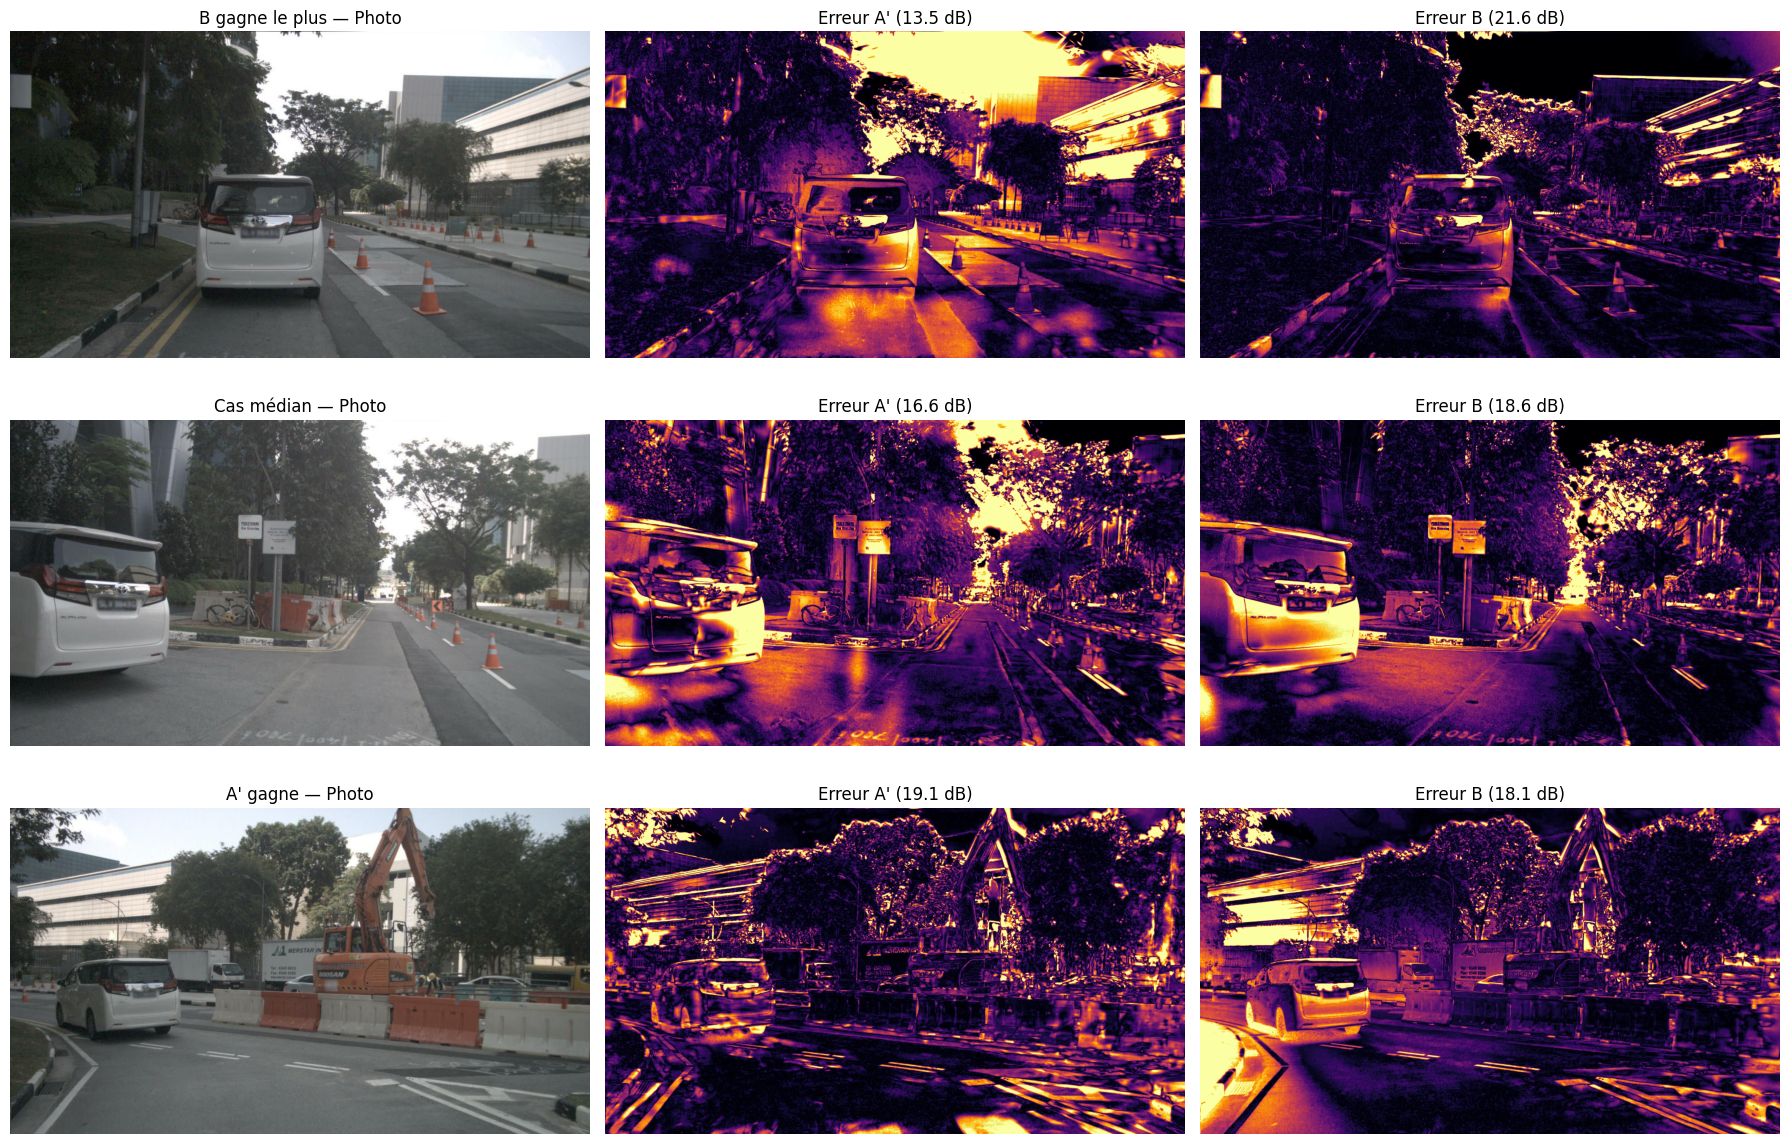

In [39]:
# Trois cas : plus gros avantage de B, cas médian, et un cas où A' gagne
diff = scores[:, 1] - scores[:, 0]          # > 0 : B meilleur
cas = {'B gagne le plus': np.argmax(diff),
       'Cas médian': np.argsort(diff)[len(diff) // 2],
       "A' gagne": np.argmin(diff)}

fig, ax = plt.subplots(3, 3, figsize=(18, 12))
for row, (titre, i) in enumerate(cas.items()):
    y, a, b = imgs[i]
    ax[row, 0].imshow(y); ax[row, 0].set_title(f'{titre} — Photo')
    ax[row, 1].imshow(np.abs(a - y).mean(-1), cmap='inferno', vmax=0.3); ax[row, 1].set_title(f"Erreur A' ({scores[i, 0]:.1f} dB)")
    ax[row, 2].imshow(np.abs(b - y).mean(-1), cmap='inferno', vmax=0.3); ax[row, 2].set_title(f"Erreur B ({scores[i, 1]:.1f} dB)")
for x in ax.flat: x.axis('off')
plt.tight_layout(); plt.show()

### Comparaison image par image (A' vs B)

#### Résultat
- **B obtient un meilleur PSNR que A' sur 49 des 52 images de test.**
- Image où l'écart est maximal : **A' 13,5 dB, B 21,6 dB** (+8,1 dB, soit une erreur quadratique environ 6,5 fois plus faible pour B).
- Cartes d'erreur $|\text{rendu} - \text{photo}|$ sur cette image :
  - **A'** : erreurs fortes et étendues, surtout sur le **ciel** et la **route** ;
  - **B** : erreurs faibles, concentrées sur de **fines lignes le long des contours** (arbres, bâtiments, bords de la voiture) ;
  - les deux modèles se trompent sur la **voiture blanche en mouvement** devant l'ego-véhicule.

#### Analyse
- L'avantage de B est **systématique** (49/52), et non un effet de moyenne tiré par quelques images.
- Les grandes zones mal reconstruites par A' (ciel, route) suggèrent qu'aucune image d'entraînement n'est assez proche de certaines vues de test. Les sweeps de B **comblent ces trous** entre keyframes.
- Les erreurs résiduelles de B, sur les contours, sont typiques d'un léger flou ou d'un petit décalage géométrique. C'est cohérent avec un LPIPS inchangé : B est plus **juste**, sans être perçu comme beaucoup plus **net**.
- Les objets **mobiles** restent mal reconstruits par les deux modèles : c'est une limite de l'hypothèse de **scène statique** du 3DGS, que les sweeps ne corrigent pas.

#### Conclusion
Ajouter les sweeps améliore la reconstruction de façon **systématique** sur les vues de test, en particulier là où les keyframes laissent des trous entre deux vues. Les erreurs restantes sont dominées par les **contours** et les **objets mobiles**.

#### Questions
1. Avec plus d'itérations (30 000), B réduit-il aussi ses erreurs de contour (meilleur LPIPS) ? Je pense que Oui.
2. Quelle part de l'erreur restante vient des objets mobiles ? On pourrait la mesurer en masquant les véhicules grâce aux boîtes 3D de `sample_annotation`. 

In [40]:
# # B' : données de B, 30 000 itérations, en arrière-plan sur le GPU n°1
# import subprocess, os
# cmd = ['ns-train', 'splatfacto',
#        '--data', '/kaggle/working/nerf_data_B',
#        '--output-dir', '/kaggle/working/outputs',
#        '--experiment-name', 'nerf_data_B_30k',
#        '--max-num-iterations', '30000',
#        '--viewer.quit-on-train-completion', 'True',
#        '--pipeline.model.num-downscales', '2',
#        'nerfstudio-data']
# log = open('/kaggle/working/train_B_30k.log', 'w')
# proc_Bp = subprocess.Popen(cmd, stdout=log, stderr=subprocess.STDOUT,
#                            env={**os.environ, 'CUDA_VISIBLE_DEVICES': '1'})
# print('B\' lancé, PID', proc_Bp.pid)

In [41]:
# !ns-train splatfacto --data /kaggle/working/nerf_data_C --output-dir /kaggle/working/outputs --max-num-iterations 7000 --viewer.quit-on-train-completion True --pipeline.model.num-downscales 2 nerfstudio-data

In [42]:
# 1. PSNR / SSIM / LPIPS sur les 52 images de test, B (7k) vs B' (30k)
import glob, json
cfg = sorted(glob.glob('/kaggle/working/outputs/nerf_data_B_30k/splatfacto/*/config.yml'))[-1]
!TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD=1 ns-eval --load-config {cfg} --output-path /kaggle/working/eval_nerf_data_B_30k.json

for name in ['nerf_data_B', 'nerf_data_B_30k']:
    r = json.load(open(f'/kaggle/working/eval_{name}.json'))['results']
    print(f"{name:16s} | PSNR {r['psnr']:.2f} | SSIM {r['ssim']:.3f} | LPIPS {r['lpips']:.3f}")

/usr/local/lib/python3.12/dist-packages/nerfstudio/field_components/activations.py:32: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @custom_fwd(cast_inputs=torch.float32)
/usr/local/lib/python3.12/dist-packages/nerfstudio/field_components/activations.py:38: FutureWarning: `torch.cuda.amp.custom_bwd(args...)` is deprecated. Please use `torch.amp.custom_bwd(args..., device_type='cuda')` instead.
  @custom_bwd
[10:16:27] Auto image downscale factor of 1                                                 ]8;id=983534;file:///usr/local/lib/python3.12/dist-packages/nerfstudio/data/dataparsers/nerfstudio_dataparser.py\nerfstudio_dataparser.py]8;;\:]8;id=175135;file:///usr/local/lib/python3.12/dist-packages/nerfstudio/data/dataparsers/nerfstudio_dataparser.py#484\484]8;;\
            Dataset is overriding train_indices to [1, 2, 3, 4, 5, 7, 8, 9, 10, 11, 14, 16, ]8;id=625576;file:///usr/local/

In [43]:
# # 2. Rendus des images d'entraînement (172) et de test (52) pour B et B'
# for name in ['nerf_data_B', 'nerf_data_B_30k']:
#     cfg = sorted(glob.glob(f'/kaggle/working/outputs/{name}/splatfacto/*/config.yml'))[-1]
#     for split in ['train', 'test']:
#         !TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD=1 ns-render dataset --load-config {cfg} --split {split} --rendered-output-names rgb --output-path /kaggle/working/renders_split/{name}

/usr/local/lib/python3.12/dist-packages/nerfstudio/field_components/activations.py:32: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @custom_fwd(cast_inputs=torch.float32)
/usr/local/lib/python3.12/dist-packages/nerfstudio/field_components/activations.py:38: FutureWarning: `torch.cuda.amp.custom_bwd(args...)` is deprecated. Please use `torch.amp.custom_bwd(args..., device_type='cuda')` instead.
  @custom_bwd
[10:17:06]  Dataset is overriding train_indices to [1, 2, 3, 4, 5, 7, 8, 9, 10, 11, 14, 16, ]8;id=231812;file:///usr/local/lib/python3.12/dist-packages/nerfstudio/data/dataparsers/nerfstudio_dataparser.py\nerfstudio_dataparser.py]8;;\:]8;id=605651;file:///usr/local/lib/python3.12/dist-packages/nerfstudio/data/dataparsers/nerfstudio_dataparser.py#203\203]8;;\
           17, 18, 19, 20, 21, 22, 23, 24, 26, 27, 28, 29, 31, 32, 33, 35, 36, 37, 38, 39,                              
   

In [44]:
# 3. PSNR train vs test (surapprentissage ?) + nombre d'images de test où B' bat B
import os, numpy as np
from PIL import Image

def load(p, size=None):
    im = Image.open(p).convert('RGB')
    return np.asarray(im.resize(size) if size else im, dtype=np.float32) / 255

psnr = lambda a, b: 10 * np.log10(1 / np.mean((a - b) ** 2))

def split_psnr(name, split):
    out = {}
    for f in glob.glob(f'/kaggle/working/renders_split/{name}/{split}/**/*.jpg', recursive=True):
        t = os.path.splitext(os.path.basename(f))[0]
        y = load(glob.glob(f'/kaggle/working/nerf_data_B/images/{t}.*')[0])
        out[t] = psnr(load(f, (y.shape[1], y.shape[0])), y)
    return out

res = {n: {s: split_psnr(n, s) for s in ['train', 'test']} for n in ['nerf_data_B', 'nerf_data_B_30k']}

print(f"{'Modèle':16s} | {'PSNR train':>10s} | {'PSNR test':>9s} | {'Écart':>6s}")
for n, r in res.items():
    tr, te = np.mean(list(r['train'].values())), np.mean(list(r['test'].values()))
    print(f"{n:16s} | {tr:10.2f} | {te:9.2f} | {tr - te:6.2f}")

tB, tBp = res['nerf_data_B']['test'], res['nerf_data_B_30k']['test']
wins = sum(tBp[t] > tB[t] for t in tB)
print(f"\nB' meilleur que B sur {wins} / {len(tB)} images de test")

Modèle           | PSNR train | PSNR test |  Écart
nerf_data_B      |      24.22 |     21.72 |   2.50
nerf_data_B_30k  |      26.84 |     20.59 |   6.25

B' meilleur que B sur 25 / 52 images de test


In [45]:
# Tableau combiné B vs B' : test (ns-eval), train vs test, images gagnées
import json, numpy as np, pandas as pd

modeles = {'B (7k)': 'nerf_data_B', "B' (30k)": 'nerf_data_B_30k'}
lignes = {}
for label, name in modeles.items():
    r  = json.load(open(f'/kaggle/working/eval_{name}.json'))['results']
    tr = np.mean(list(res[name]['train'].values()))
    te = np.mean(list(res[name]['test'].values()))
    lignes[label] = {'PSNR train ↑': tr, 'PSNR test ↑': te, 'Écart train − test': tr - te,
                     'SSIM test ↑': r['ssim'], 'LPIPS test ↓': r['lpips']}

df = pd.DataFrame(lignes).T
df.loc["Écart B' − B"] = df.loc["B' (30k)"] - df.loc['B (7k)']
display(df.round(3))

tB, tBp = res['nerf_data_B']['test'], res['nerf_data_B_30k']['test']
print(f"B' meilleur que B sur {sum(tBp[t] > tB[t] for t in tB)} / {len(tB)} images de test")

,PSNR train ↑,PSNR test ↑,Écart train − test,SSIM test ↑,LPIPS test ↓
B (7k),24.216,21.719,2.497,0.763,0.515
B' (30k),26.838,20.591,6.247,0.738,0.460
Écart B' − B,2.622,-1.128,3.750,-0.025,-0.054


B' meilleur que B sur 25 / 52 images de test


In [46]:
# Vidéo [vraie frames | B (7k) | B' (30k)] sur les 52 vues de test, dans l'ordre du trajet
import glob, os, json, numpy as np, mediapy as media
from PIL import Image, ImageDraw
from IPython.display import Video

def renders(name):
    files = glob.glob(f'/kaggle/working/renders_split/{name}/test/**/*.jpg', recursive=True)
    return {os.path.splitext(os.path.basename(f))[0]: f for f in files}

rB, rBp = renders('nerf_data_B'), renders('nerf_data_B_30k')
sds = {s['token']: s for s in json.load(open('/kaggle/working/data/sets/nuscenes/v1.0-mini/sample_data.json'))}
tokens = sorted(set(rB) & set(rBp), key=lambda t: sds[t]['timestamp'])
print(len(tokens), 'images de test')

def tile(path, label, size=(533, 300)):
    im = Image.open(path).convert('RGB').resize(size)
    ImageDraw.Draw(im).text((10, 10), label, fill=(255, 255, 0))
    return np.array(im)

frames = [np.concatenate([tile(glob.glob(f'/kaggle/working/nerf_data_B/images/{t}.*')[0], 'Photo'),
                          tile(rB[t], 'B (7k)'),
                          tile(rBp[t], "B' (30k)")], axis=1) for t in tokens]

media.write_video('/kaggle/working/renders/test_photo_B_Bprime.mp4', frames, fps=3)
Video('/kaggle/working/renders/test_photo_B_Bprime.mp4', embed=True, width=1000)

52 images de test


In [47]:
# Vidéo [vraie frames | B (7k) | B' (30k)] — split = 'train' (172 images) ou 'test' (52 images)
import glob, os, json, numpy as np, mediapy as media
from PIL import Image, ImageDraw
from IPython.display import Video

split = 'train'

def renders(name):
    files = glob.glob(f'/kaggle/working/renders_split/{name}/{split}/**/*.jpg', recursive=True)
    return {os.path.splitext(os.path.basename(f))[0]: f for f in files}

rB, rBp = renders('nerf_data_B'), renders('nerf_data_B_30k')
sds = {s['token']: s for s in json.load(open('/kaggle/working/data/sets/nuscenes/v1.0-mini/sample_data.json'))}
tokens = sorted(set(rB) & set(rBp), key=lambda t: sds[t]['timestamp'])
print(len(tokens), f'images ({split})')

def tile(path, label, size=(533, 300)):
    im = Image.open(path).convert('RGB').resize(size)
    ImageDraw.Draw(im).text((10, 10), label, fill=(255, 255, 0))
    return np.array(im)

frames = [np.concatenate([tile(glob.glob(f'/kaggle/working/nerf_data_B/images/{t}.*')[0], 'Photo'),
                          tile(rB[t], 'B (7k)'),
                          tile(rBp[t], "B' (30k)")], axis=1) for t in tokens]

out = f'/kaggle/working/renders/{split}_photo_B_Bprime.mp4'
media.write_video(out, frames, fps=12 if split == 'train' else 3)
Video(out, embed=True, width=1000)

172 images (train)


### Analyse
- **Le PSNR train monte (+2,6 dB) pendant que le PSNR test baisse (−1,1 dB).** Avec 4 fois plus d'itérations,
  B' continue d'apprendre ses 172 images d'entraînement, mais ce gain ne se transmet pas aux vues de test : il
  s'en éloigne même. C'est la définition du **surapprentissage**.
- **L'écart train − test est multiplié par 2,5** (2,5 → 6,2 dB). B généralisait déjà imparfaitement ; B' généralise
  nettement moins bien.
- **La SSIM baisse aussi (−0,025)** : les structures locales des vues de test sont moins bien reproduites.
- **Le LPIPS s'améliore (−0,054)** : B' produit des détails plus fins et des textures plus nettes, que le réseau
  perceptuel apprécie. Mais une partie de ces détails est **propre aux vues d'entraînement** et se retrouve mal
  placée sur les nouvelles vues, ce que le PSNR pénalise (« net mais faux »).
- **B' ne bat B que sur 25 images de test sur 52** : pile ou face, sans avantage systématique.
  À comparer avec B contre A' (49 / 52) : ajouter des **vues** aide beaucoup plus qu'ajouter des **itérations**.
- **Cause probable** : la caméra ne voit la scène que depuis une trajectoire frontale. Au-delà d'un certain budget,
  le modèle ne peut plus améliorer la géométrie (faute de points de vue variés) et se met à mémoriser les
  détails de chaque image.
- **Limites** : une seule scène, un seul entraînement par configuration, seulement deux budgets testés.

### Conclusion
Sur cette scène, **30 000 itérations font surapprendre le modèle** : meilleur sur l'entraînement, moins bon sur les
vues inédites, malgré des rendus perçus comme plus nets. Pour un objectif de **synthèse de nouvelles vues**,
**7 000 itérations restent le meilleur choix** parmi les deux testés, et serviront de budget de référence pour la suite.
Le levier efficace pour progresser n'est pas le temps d'entraînement, mais **la qualité et la diversité de l'information
géométrique** (plus de vues, meilleure initialisation).

### Questions
1. Où se situe le meilleur nombre d'itérations entre 7 000 et 30 000 (10 000 ? 15 000 ?) ?
2. L'initialisation par le lidar (modèle C) rend il l'entrainement plus robuste ?
3. Ajouter d'autres caméras (`CAM_FRONT_LEFT/RIGHT`) permettrait-il de profiter de plus d'itérations sans surapprendre ?

In [48]:
# 4. Nombre de gaussiennes de chaque modèle
import torch
for name in ['nerf_data_B', 'nerf_data_B_30k']:
    ckpt = sorted(glob.glob(f'/kaggle/working/outputs/{name}/splatfacto/*/nerfstudio_models/*.ckpt'))[-1]
    sd = torch.load(ckpt, map_location='cpu', weights_only=False)['pipeline']
    n = next(v.shape[0] for k, v in sd.items() if k.endswith('gauss_params.means'))
    print(f'{name:16s} | {n:,} gaussiennes')

nerf_data_B      | 338,587 gaussiennes
nerf_data_B_30k  | 463,446 gaussiennes


In [49]:
!grep -n "refine_every\|stop_split_at\|cull_alpha_thresh\|reset_alpha_every" /kaggle/working/outputs/nerf_data_B/splatfacto/*/config.yml

183:    cull_alpha_thresh: 0.1
206:    refine_every: 100
207:    reset_alpha_every: 30
214:    stop_split_at: 15000


## Expériance 3':  Track du nombre d'itération optimal

### Motivation
L'expérience précédente (B à 7 000 contre B' à 30 000 itérations) a révélé un **surapprentissage** : au-delà d'un
certain point, le PSNR d'entraînement continue de monter tandis que le PSNR de test baisse.
Mais elle ne compare que **deux** budgets, et ce choix a été fait en regardant le **test**, ce qui biaise légèrement
le score final. On cherche ici le **meilleur nombre d'itérations** de façon rigoureuse.

### Objectif
Tracer l'évolution des métriques en fonction du nombre d'itérations, et choisir l'optimum **sur un jeu de validation**,
sans jamais utiliser le test pour décider.

### Protocole
1. **Découpage en trois** (scène `scene-0061`, caméra `CAM_FRONT`, keyframes + sweeps) :
   - **test** : une keyframe sur 5 (3ᵉ de chaque groupe) + les sweeps à moins de 0,25 s → les **mêmes 52 images**
     que dans les expériences précédentes ;
   - **validation** : une autre keyframe sur 5 (5ᵉ de chaque groupe) + ses sweeps à moins de 0,25 s ;
   - **train** : toutes les autres images.

   Aucune image de validation ou de test n'est vue à l'entraînement.
2. **Un seul entraînement long** (30 000 itérations, réglages splatfacto par défaut), avec un **checkpoint toutes les
   3 000 itérations**.
3. **Évaluation de chaque checkpoint** sur le **train** et sur la **validation** : PSNR, SSIM, LPIPS.
4. **Courbes** des métriques en fonction du nombre d'itérations, train et validation sur le même graphique.
5. **Choix** du nombre d'itérations qui maximise le PSNR de **validation**.
6. **Évaluation finale, une seule fois, sur le test**, du checkpoint choisi.

### Pourquoi un seul entraînement suffit
Dans splatfacto, la décroissance du taux d'apprentissage est fixée sur 30 000 itérations, quelle que soit la durée
de l'entraînement. Le checkpoint à l'itération *k* d'un entraînement long est donc équivalent à un entraînement
arrêté à *k*. Pas besoin de réentraîner un modèle à la fin : le checkpoint choisi **est** le modèle final.

### Hypothèses
- La validation devrait **monter puis redescendre** (ou stagner), tandis que le train monte jusqu'au bout.
- L'optimum devrait se situer **entre 7 000 et 15 000 itérations**, avant la fin de la densification (`stop_split_at = 15 000`).
- Le LPIPS pourrait continuer de s'améliorer plus longtemps que le PSNR (« net mais faux »).

### Limites attendues
- Une seule scène et un seul entraînement : pas de mesure de la variabilité.
- Moins d'images d'entraînement que B (une partie sert à la validation) : les scores ne sont pas directement
  comparables à ceux des expériences précédentes.

In [50]:
# Export train / validation / test : test et validation = fenêtres de 0,25 s autour de keyframes réservées
import os, json, shutil
import numpy as np

OPENCV_TO_OPENGL = np.diag([1, -1, -1, 1])

def export_tvt(dataroot, output_dir, version='v1.0-mini', channel='CAM_FRONT', scene_idx=0,
               every=5, test_pos=2, val_pos=4, gap_s=0.25):
    t = load_tables(dataroot, version)
    by = lambda tab: {r['token']: r for r in tab}
    sensors, calibs, poses, sds = by(t['sensor']), by(t['calibrated_sensor']), by(t['ego_pose']), by(t['sample_data'])

    # Toutes les images de la caméra dans la scène, dans l'ordre (chaîne 'next')
    first_sample = t['scene'][scene_idx]['first_sample_token']
    sd = next(s for s in t['sample_data']
              if s['sample_token'] == first_sample and s['is_key_frame']
              and sensors[calibs[s['calibrated_sensor_token']]['sensor_token']]['channel'] == channel)
    chain = []
    while sd:
        chain.append(sd)
        sd = sds.get(sd['next'])

    kf = [s for s in chain if s['is_key_frame']]
    test_ts = [s['timestamp'] for i, s in enumerate(kf) if i % every == test_pos]
    val_ts  = [s['timestamp'] for i, s in enumerate(kf) if i % every == val_pos]
    near = lambda s, L: min(abs(s['timestamp'] - x) for x in L) <= gap_s * 1e6

    shutil.rmtree(output_dir, ignore_errors=True)
    os.makedirs(f'{output_dir}/images')
    frames, splits = [], {'train': [], 'val': [], 'test': []}
    for s in chain:
        split = 'test' if near(s, test_ts) else 'val' if near(s, val_ts) else 'train'
        T = get_T(poses[s['ego_pose_token']]) @ get_T(calibs[s['calibrated_sensor_token']]) @ OPENCV_TO_OPENGL
        name = f"./images/{s['token']}.{s['fileformat']}"
        shutil.copy(os.path.join(dataroot, s['filename']), os.path.join(output_dir, name))
        frames.append({'file_path': name, 'transform_matrix': T.tolist()})
        splits[split].append(name)

    K = calibs[chain[0]['calibrated_sensor_token']]['camera_intrinsic']
    data = {'fl_x': K[0][0], 'fl_y': K[1][1], 'cx': K[0][2], 'cy': K[1][2],
            'w': chain[0]['width'], 'h': chain[0]['height'], 'frames': frames,
            'train_filenames': splits['train'], 'val_filenames': splits['val'], 'test_filenames': splits['test']}
    with open(f'{output_dir}/transforms.json', 'w') as f:
        json.dump(data, f, indent=4)
    print(f"{output_dir} : train {len(splits['train'])} | val {len(splits['val'])} | test {len(splits['test'])}")

export_tvt(DATAROOT, '/kaggle/working/nerf_data_tvt')

/kaggle/working/nerf_data_tvt : train 125 | val 47 | test 52


In [51]:
# # Expérience 3' : 30 000 itérations, checkpoint toutes les 3 000, en arrière-plan sur le GPU n°1
# import subprocess, os
# cmd = ['ns-train', 'splatfacto',
#        '--data', '/kaggle/working/nerf_data_tvt',
#        '--output-dir', '/kaggle/working/outputs',
#        '--max-num-iterations', '30000',
#        '--steps-per-save', '3000',
#        '--save-only-latest-checkpoint', 'False',
#        '--viewer.quit-on-train-completion', 'True',
#        '--pipeline.model.num-downscales', '2',
#        'nerfstudio-data']
# log = open('/kaggle/working/train_tvt.log', 'w')
# proc_tvt = subprocess.Popen(cmd, stdout=log, stderr=subprocess.STDOUT,
#                             env={**os.environ, 'CUDA_VISIBLE_DEVICES': '1'})
# print('Entraînement lancé, PID', proc_tvt.pid)

In [52]:
# Expérience 5 : métriques train / validation pour chaque checkpoint (calcul long)
import os, glob, re, json, torch, numpy as np
from pathlib import Path

RUN_EVAL = False   # True seulement pour refaire le calcul

if RUN_EVAL:
    os.environ['TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD'] = '1'
    from nerfstudio.utils.eval_utils import eval_setup

    run   = sorted(glob.glob('/kaggle/working/outputs/nerf_data_tvt/splatfacto/*/'))[-1]
    ckpts = sorted(glob.glob(run + 'nerfstudio_models/step-*.ckpt'))
    steps = [int(re.search(r'step-(\d+)', c).group(1)) for c in ckpts]
    print(len(ckpts), 'checkpoints :', steps)

    # test_mode='val' : le jeu d'évaluation chargé est la VALIDATION (le test n'est jamais touché)
    _, pipeline, _, _ = eval_setup(Path(run) / 'config.yml', test_mode='val')
    dm, model = pipeline.datamanager, pipeline.model

    def train_metrics():
        vals = []
        for i in range(len(dm.train_dataset)):
            cam = dm.train_dataset.cameras[i:i + 1].to(pipeline.device)
            img = (dm.cached_train[i] if hasattr(dm, 'cached_train') else dm.train_dataset[i])['image']
            with torch.no_grad():
                out = model.get_outputs_for_camera(cam)
                m, _ = model.get_image_metrics_and_images(out, {'image': img.to(pipeline.device)})
            vals.append(m)
        return {k: float(np.mean([v[k] for v in vals])) for k in ('psnr', 'ssim', 'lpips')}

    results = []
    for step, ck in zip(steps, ckpts):
        sd = torch.load(ck, map_location='cpu', weights_only=False)
        pipeline.load_pipeline(sd['pipeline'], sd['step'])
        pipeline.eval()
        tr = train_metrics()
        va = pipeline.get_average_eval_image_metrics(step=step)
        results.append({'step': step, 'n_gauss': model.num_points,
                        **{f'train_{k}': tr[k] for k in tr},
                        **{f'val_{k}': float(va[k]) for k in ('psnr', 'ssim', 'lpips')}})
        print(f"{step:6d} | train PSNR {tr['psnr']:.2f} | val PSNR {va['psnr']:.2f} | val LPIPS {va['lpips']:.3f}")

    json.dump(results, open('/kaggle/working/exp5_curves.json', 'w'), indent=2)

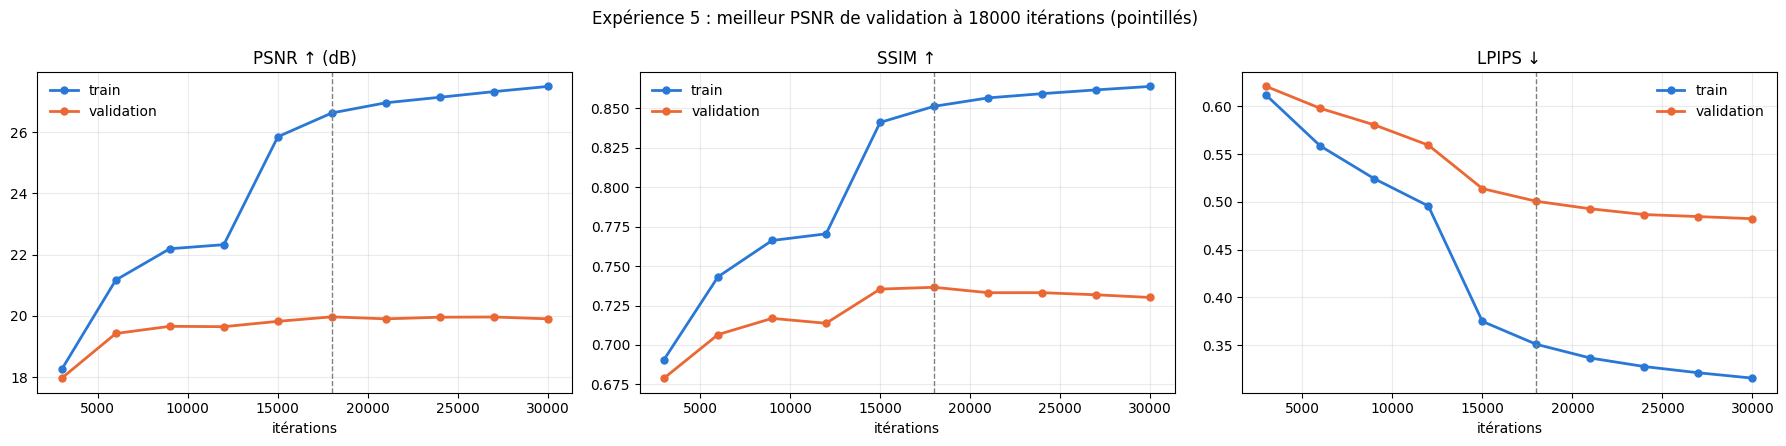

In [53]:
# Expérience 5 : courbes train / validation, relues depuis exp5_curves.json (aucun recalcul)
import json
import matplotlib.pyplot as plt

results = json.load(open('/kaggle/working/exp5_curves.json'))

# Une figure par métrique, train et validation sur le même axe
x = [r['step'] for r in results]
best = max(results, key=lambda r: r['val_psnr'])['step']
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, (k, titre) in zip(axes, [('psnr', 'PSNR ↑ (dB)'), ('ssim', 'SSIM ↑'), ('lpips', 'LPIPS ↓')]):
    ax.plot(x, [r[f'train_{k}'] for r in results], '-o', color='#2a78d6', lw=2, ms=5, label='train')
    ax.plot(x, [r[f'val_{k}'] for r in results], '-o', color='#eb6834', lw=2, ms=5, label='validation')
    ax.axvline(best, color='0.5', ls='--', lw=1)
    ax.set_title(titre); ax.set_xlabel('itérations'); ax.grid(alpha=.25); ax.legend(frameon=False)
fig.suptitle(f'Expérience 5 : meilleur PSNR de validation à {best} itérations (pointillés)')
plt.tight_layout()
plt.savefig('/kaggle/working/exp5_curves.png', dpi=120)
plt.show()

Interprétation des coubres.
Prenons le graphique PSNR. Les deux autres se lisent un peu pareillement. Pour le PSNR, plus haut va la courbe et mieux c'est.
- De 3k à 9k itérations les deux courbes montent. Le modède est en plein apprentissage de la scène.
- Au delà de 9k itérations le modèle continue de performer sur les données d'entrainement mais ne comprends pas mieux la scène.
- Plus l'écart entre les deux courbe grandi ensuite et plus le modèle sur-apprend les données d'apprentissage.
  En pointillé on marque l’endroit où l’orange est le plus haut (18 000 environ) : le meilleur moment pour arrêter.


Pour le LPIPS c'est l'inverse. (plus bas = mieux). Donc la descente simultanée des deux courbes montre que le modèle apprend, ensuite la courbe orange va sembler converger alors que la bleue continue de descendre. C'est le cas d'école du modèle qui cesse de mieux généraliser mais continue de mémoriser les données d'entrainements.

Dans la suite, on va donc fixer le N_iter à 18k pour valider d'autres expériences. Attention ceci ne veut pas dire que 18k iter est la valeur générale qu'il faut pour apprendre toute scène quand on fait du 3DGS. Juste elle fit mieux la scène 0061 qui nous sert dans le projet.

---
**Suite :** partie 3, initialisation des gaussiennes par le lidar et apprentissage avec 3 caméras.
